In [1]:
import time 
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.stats import randint, uniform, loguniform
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import GroupKFold, GridSearchCV, RandomizedSearchCV, cross_val_score
from xgboost import XGBRegressor

In [2]:
## Loading the data

D = Path("../data/teaching") if Path("../data/teaching").exists() else Path("data/teaching")
db = pd.read_csv(D / "capture_cleaned.csv").merge(pd.read_csv(D / "isotope_features.csv"), on=["Z", "A"])   ## Appending extra isotope features to the data
ev = pd.read_csv(D / "endf_Au197_capture.csv")

## Defining our features

db["logE"], db["logS"] = np.log10(db.energy_eV), np.log10(db.sigma_b * 1000)    ### logS is what we want to predict
db["iso"] = db.Z * 1000 + db.A                                                  ### We give each isotope a unique number so we can use in validation
features = ["Z", "A", "logE"]
features10 = features + ["N", "Q_capture", "S_n", "B_per_A", "Z_odd", "N_odd", "N_magic_dist"]

### Defining our error function:

def errors(model, df, feats= features):                     ## Returns RMS and Median Factor
    r = model.predict(df[feats]) - df.logS
    return 10 ** np.sqrt(np.mean(r**2)), 10**np.median(np.abs(r)) 

## Defining function to auto hold out one isotope:

def split(Z,A):
    t = db[(db.Z == Z) & (db.A == A)]
    return db.drop(t.index), t 

## Now holding out gold (Au-197) from the training set:
train, test = split(79, 197)

## Defining an energy space:
E = np.logspace(5, np.log10(2e7), 400) ; grid = pd.DataFrame({"Z": 79, "A": 197, "logE": np.log10(E)})

## Hyperparameters

Train tree with different max_depth and min_samples_leaf

max_depth  gold RMS  gold median  training RMS  training median  other isotopes RMS
        1      3.70         3.88          5.49             2.95                6.06
        2      2.23         1.76          4.41             2.38                5.84
        3      1.67         1.45          3.63             2.12                4.40
        4      1.65         1.63          3.23             1.91                4.51
        6      1.39         1.31          2.61             1.59                3.79
        8      1.29         1.15          2.11             1.34                4.47
       12      1.32         1.26          1.65             1.16                4.71
     none      1.66         1.66          1.55             1.11                4.96
min_samples_leaf  gold RMS  gold median  training RMS  training median  other isotopes RMS
               1      1.71         1.60          1.15             1.00                5.05
               5      1.66         1.66          1.55         

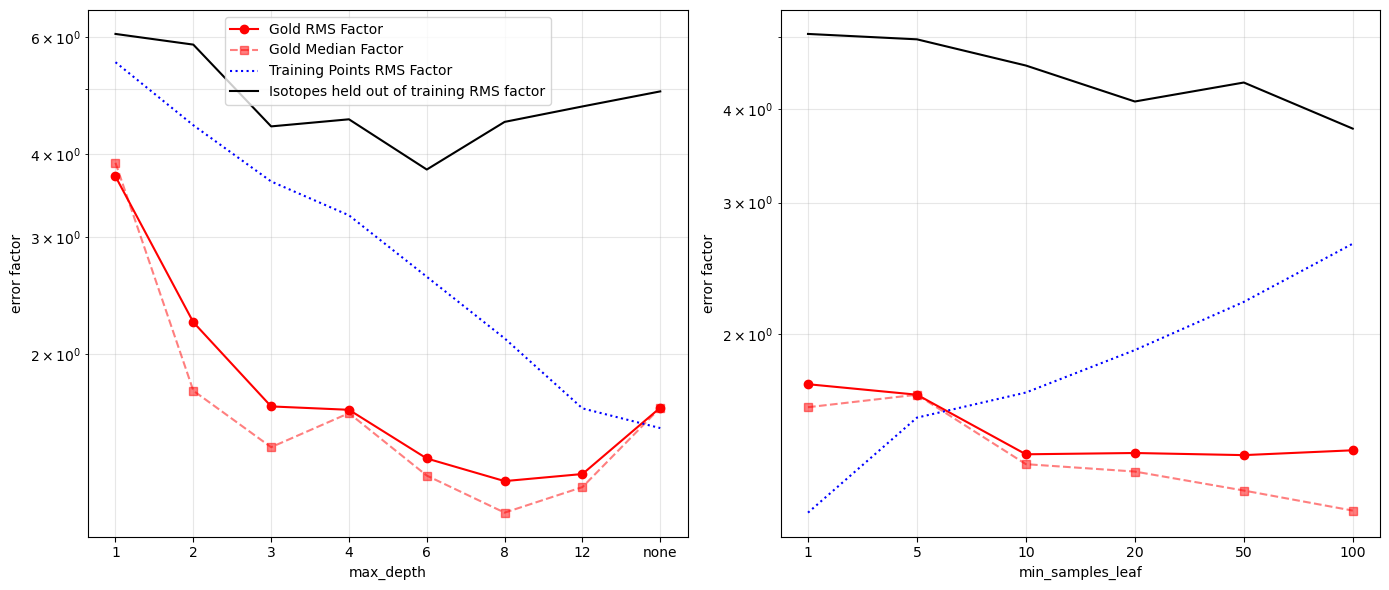

In [3]:
## Define a function that can easily sweep across multiple parameters and evaluate model performance

def sweep(name, settings):
    rows = []
    for s in settings:
        m = DecisionTreeRegressor(random_state=0, **s).fit(train[features], train.logS)
        val = 10 ** np.sqrt(-cross_val_score(DecisionTreeRegressor(random_state=0, **s), 
                                             train[features], train.logS, 
                                             groups = train.iso, 
                                             cv = GroupKFold(5), 
                                             scoring= "neg_mean_squared_error").mean())
        rows.append([str(s[name]).replace("None", "none"), *errors(m, test), *errors(m, train), val])
    return pd.DataFrame(rows, columns=[name, "gold RMS", "gold median", "training RMS", "training median", "other isotopes RMS"])

## Sweep across max_depth parameter:

by_depth = sweep("max_depth", [dict(max_depth=d, min_samples_leaf=5) for d in [1, 2, 3, 4, 6, 8, 12, None]])

## Sweep across min_samples_leaf parameter:

by_leaf = sweep("min_samples_leaf", [dict(max_depth=None, min_samples_leaf = l) for l in [1, 5, 10, 20, 50, 100]])

print(by_depth.round(2).to_string(index=False)); print('==============='); print(by_leaf.round(2).to_string(index=False))


### Visualising the metrics:

fig, ax = plt.subplots(1, 2, figsize=(14, 6))
for a, t in zip(ax, [by_depth, by_leaf]):
    x = range(len(t)) ; a.plot(x , t["gold RMS"], "ro-", label="Gold RMS Factor") ; a.plot(x, t["gold median"], "rs--", alpha=0.5, label = "Gold Median Factor") ; a.plot(x, t['training RMS'], "b:", label="Training Points RMS Factor") ; a.plot(x ,t["other isotopes RMS"], 'k-', label="Isotopes held out of training RMS factor")
    a.set(xticks = x, xticklabels=t.iloc[:,0].astype(str), 
          xlabel=t.columns[0],
          ylabel = "error factor",
          yscale = "log")
    a.grid(alpha=0.3, which="Both")
    ax[0].legend() ; plt.tight_layout()
       

## What about absolute_error?

squared_error   gold RMS factor = 1.29, median factor = 1.15, training time = 0.008 s
absolute_error  gold RMS factor = 1.35, median factor = 1.28, training time = 0.518 s


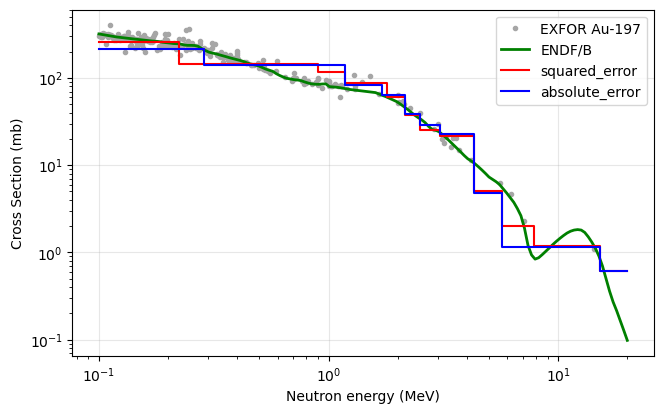

In [4]:
fig, ax = plt.subplots(figsize=(7.5, 4.5))
ax.plot(test.energy_eV / 1e6, test.sigma_b * 1000, ".", color="0.65", label="EXFOR Au-197")
ax.plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "g-", lw=2, label="ENDF/B")

for crit, c in [("squared_error", "r"), ("absolute_error", "b")]:
    t0 = time.time()
    m = DecisionTreeRegressor(criterion = crit, max_depth = 8, min_samples_leaf = 5, random_state=0).fit(train[features], train.logS)
    sec = time.time() - t0
    print(f"{crit:15s} gold RMS factor = {errors(m,test)[0]:.2f}, median factor = {errors(m, test)[1]:.2f}, training time = {sec:.3f} s")

    ax.plot(E / 1e6, 10** m.predict(grid), c, drawstyle="steps-mid", label=crit)  

ax.set(
    xscale = "log",
    yscale = "log",
    xlabel = "Neutron energy (MeV)",
    ylabel = "Cross Section (mb)"
)
ax.legend() ; ax.grid(alpha=0.3)

## Is gold easier or harder to predict than other isotopes held out?

In [5]:
rows = []
for name, (Z,A) in {"Au-197 (gold)": (79, 197), "U-238": (92, 238), "Ta-181": (73, 181), "Rh-103" : (45,103), "Ag-107": (47, 107), "I-127": (53,127), "Ne-22":(10,22)}.items(): 
    tr, te = split(Z,A)
    m = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0).fit(tr[features], tr.logS)
    rows.append([name, len(te), *errors(m,te)])

print(pd.DataFrame(rows, columns=["held-out isotope", "points", "RMS factor", "median factor"]).round(2).to_string(index=False))

held-out isotope  points  RMS factor  median factor
   Au-197 (gold)     300        1.29           1.15
           U-238     300        1.59           1.33
          Ta-181     190        1.60           1.30
          Rh-103     108        2.17           1.36
          Ag-107      39        1.79           1.56
           I-127     163       39.24          53.38
           Ne-22      98       73.89          19.85


## Choosing hyperparameters via optimisation

In [6]:
cv = GroupKFold(5)
groups = train.iso
score = "neg_mean_squared_error"
to_factor = lambda s: 10**np.sqrt(-s)

hand = DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0)
grid_s = GridSearchCV(DecisionTreeRegressor(random_state=0), dict(max_depth = [2,3,4,5,6,8,10,12], min_samples_leaf=[1,5,10,20,50]), cv=cv, scoring=score)
rand_s = RandomizedSearchCV(DecisionTreeRegressor(random_state=0), dict(max_depth = randint(2,16), min_samples_leaf=randint(1,60)), n_iter=40, cv=cv, scoring=score, random_state=0)

rows = [["hand-chosen", hand.get_params()["max_depth"], hand.get_params()["min_samples_leaf"],
         to_factor(cross_val_score(hand, train[features], train.logS, groups=groups, cv=cv, scoring=score).mean()), *errors(hand.fit(train[features], train.logS), test)]]

for name, s in [("grid search", grid_s), ("random search", rand_s)]:
    s.fit(train[features], train.logS, groups=groups)
    rows.append([name, s.best_params_["max_depth"], s.best_params_["min_samples_leaf"], to_factor(s.best_score_), *errors(s.best_estimator_, test)])



In [7]:
## Also using Optuna package 

import optuna

optuna.logging.set_verbosity(optuna.logging.WARNING)

def objective(t):
    m = DecisionTreeRegressor(max_depth=t.suggest_int("max_depth", 2, 15), min_samples_leaf=t.suggest_int("min_samples_leaf", 1, 60), random_state=0)
    
    return -cross_val_score(m, train[features], train.logS, groups = groups, cv = cv, scoring=score).mean()

study = optuna.create_study(sampler=optuna.samplers.TPESampler(seed=0)); study.optimize(objective, n_trials=40)
p = study.best_params; best = DecisionTreeRegressor(random_state=0, **p).fit(train[features], train.logS)
rows.append(["optuna", p["max_depth"], p["min_samples_leaf"], to_factor(-study.best_value), *errors(best, test)])
print(pd.DataFrame(rows, columns=["method", "max_depth", "min_samples_leaf", "CV factor (other isotopes)", "gold RMS factor", "gold median factor"]).round(2).to_string(index=False))

       method  max_depth  min_samples_leaf  CV factor (other isotopes)  gold RMS factor  gold median factor
  hand-chosen          8                 5                        4.47             1.29                1.15
  grid search          6                20                        3.68             1.39                1.31
random search          5                25                        3.75             1.42                1.37
       optuna          6                24                        3.68             1.39                1.31


# Comparing different models - Random forest and XGBoost with decision tree

In [8]:
spaces = {
    "tree":   (DecisionTreeRegressor(random_state=0), dict(max_depth=randint(2, 16), min_samples_leaf=randint(1, 60))),
    "forest": (RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1), dict(max_depth=randint(3, 25), min_samples_leaf=randint(1, 40), max_features=uniform(0.34, 0.66))),
    "xgboost": (XGBRegressor(random_state=0, n_jobs=-1), dict(n_estimators=randint(50, 400), max_depth=randint(2, 8), learning_rate=loguniform(0.02, 0.3), subsample=uniform(0.5, 0.5), min_child_weight=randint(1, 20))),
}
models, rows = {}, []
for name, (model, space) in spaces.items():
    t0 = time.time(); default = model.fit(train[features], train.logS); t_default = time.time() - t0
    t0 = time.time(); search = RandomizedSearchCV(model, space, n_iter=30, cv=cv, scoring=score, random_state=0).fit(train[features], train.logS, groups=groups); t_search = time.time() - t0
    models[name] = search.best_estimator_
    rows.append([name, *errors(default, test), *errors(search.best_estimator_, test), t_default, t_search])
table_c = pd.DataFrame(rows, columns=["model", "default RMS", "default median", "tuned RMS", "tuned median", "default fit (s)", "tuning (s)"]).set_index("model")
print(table_c.round(2).to_string())

         default RMS  default median  tuned RMS  tuned median  default fit (s)  tuning (s)
model                                                                                     
tree            1.71            1.60       1.42          1.37             0.02        0.99
forest          1.61            1.56       1.31          1.24             0.21       20.66
xgboost         1.46            1.40       1.20          1.07             0.13       37.47


      tree  forest  xgboost
Z     0.82    0.51     0.71
A     0.05    0.35     0.07
logE  0.13    0.13     0.22


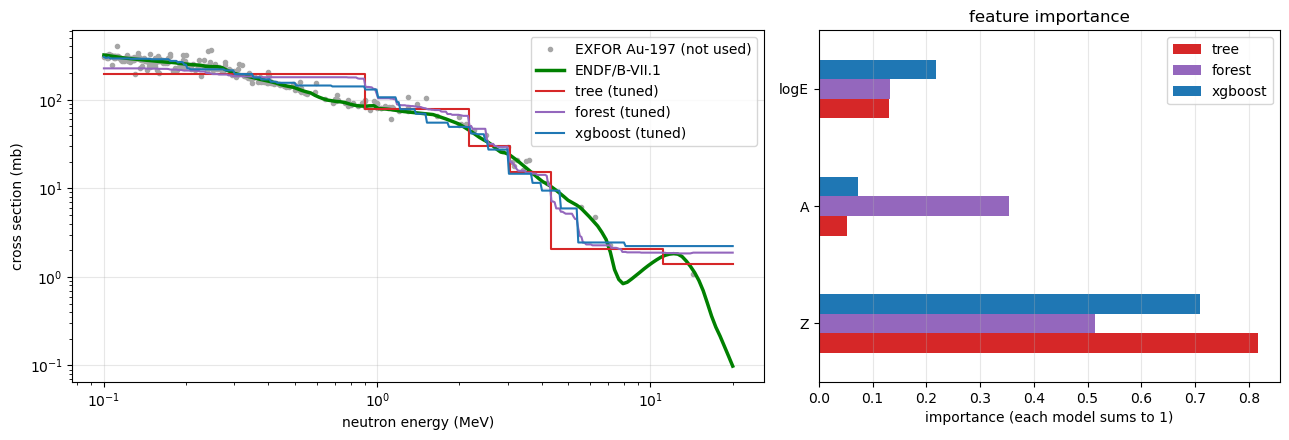

In [9]:
fig, ax = plt.subplots(1, 2, figsize=(13, 4.5), gridspec_kw={"width_ratios": [3, 2]})
ax[0].plot(test.energy_eV / 1e6, test.sigma_b * 1000, ".", color="0.65", label="EXFOR Au-197 (not used)"); ax[0].plot(ev.energy_eV / 1e6, ev.sigma_b * 1000, "g-", lw=2.5, label="ENDF/B-VII.1")
for (name, m), c in zip(models.items(), ["tab:red", "tab:purple", "tab:blue"]):
    ax[0].plot(E / 1e6, 10 ** m.predict(grid), color=c, drawstyle="steps-mid" if name == "tree" else "default", label=f"{name} (tuned)")
ax[0].set(xscale="log", yscale="log", xlabel="neutron energy (MeV)", ylabel="cross section (mb)"); ax[0].legend(); ax[0].grid(alpha=0.3)
imp = pd.DataFrame({k: m.feature_importances_ for k, m in models.items()}, index=features)
imp.plot.barh(ax=ax[1], color=["tab:red", "tab:purple", "tab:blue"]); ax[1].set(xlabel="importance (each model sums to 1)", title="feature importance"); ax[1].grid(alpha=0.3, axis="x")
plt.tight_layout(); print(imp.round(2).to_string())

## Is the comparison the same for other isotopes?

In [10]:
fixed = {"tree": lambda: DecisionTreeRegressor(max_depth=8, min_samples_leaf=5, random_state=0), "forest": lambda: RandomForestRegressor(n_estimators=100, random_state=0, n_jobs=-1), "xgboost": lambda: XGBRegressor(random_state=0, n_jobs=-1)}
isotopes = {"Au-197": (79, 197), "U-238": (92, 238), "Ta-181": (73, 181), "Rh-103": (45, 103), "Ag-107": (47, 107), "W-186": (74, 186), "Hf-178": (72, 178), "Gd-158": (64, 158), "Ba-138": (56, 138), "I-127": (53, 127)}
rows = []
for name, (Z, A) in isotopes.items():
    tr, te = split(Z, A)
    rows.append([name] + [errors(mk().fit(tr[features], tr.logS), te)[0] for mk in fixed.values()])
cmp_ = pd.DataFrame(rows, columns=["held-out isotope", *fixed]).set_index("held-out isotope")
print(cmp_.round(2).to_string())
print("\ngeometric mean over these isotopes:", np.exp(np.log(cmp_).mean()).round(2).to_dict())
print("number of isotopes where each model is the best:", cmp_.idxmin(axis=1).value_counts().to_dict())

                   tree  forest  xgboost
held-out isotope                        
Au-197             1.29    1.61     1.46
U-238              1.59    2.03     1.42
Ta-181             1.60    4.04     3.83
Rh-103             2.17    2.09     7.64
Ag-107             1.79    1.67     1.54
W-186              2.54    3.09     2.62
Hf-178             2.02   10.55    10.35
Gd-158             2.24    1.65     1.88
Ba-138             3.38    2.90    27.03
I-127             39.24   42.23     2.16

geometric mean over these isotopes: {'tree': 2.68, 'forest': 3.53, 'xgboost': 3.5}
number of isotopes where each model is the best: {'tree': 4, 'xgboost': 3, 'forest': 3}


## Training on 10 features - Do more features mean better results?

In [11]:
rows = []
for name, m in [("tree", models["tree"]), ("forest", models["forest"]), ("xgboost", models["xgboost"])]:
    m10 = m.__class__(**m.get_params()).fit(train[features10], train.logS)                      # the same settings, ten features
    rows.append([name, *errors(m, test), *errors(m10, test, features10)])
print(pd.DataFrame(rows, columns=["model (tuned settings)", "3 features: RMS", "median", "10 features: RMS", "median"]).round(2).to_string(index=False))


model (tuned settings)  3 features: RMS  median  10 features: RMS  median
                  tree             1.42    1.37              2.05    1.49
                forest             1.31    1.24              1.79    1.47
               xgboost             1.20    1.07              2.02    2.02


In [13]:
bins = np.floor(db.logE * 8)                                                                     # the look-alike test of T1 section 10
curve = db.groupby([db.iso, bins]).logS.median().unstack(0)
shared = curve.notna().mul(curve[79197].notna(), axis=0).sum()
distance = curve.sub(curve[79197], axis=0).abs().median()[shared >= 4].drop(79197)
alike = distance[distance < 0.3].index
hard = train[~train.iso.isin(alike)]
rows = []
for name, m in models.items():
    for label, feats in [("3 features", features), ("10 features", features10)]:
        mk = m.__class__(**m.get_params())
        rows.append([name, label, errors(mk.fit(train[feats], train.logS), test, feats)[0], errors(m.__class__(**m.get_params()).fit(hard[feats], hard.logS), test, feats)[0]])
print(f"gold-197 has {len(alike)} look-alikes (within a factor of 2)")
print(pd.DataFrame(rows, columns=["model", "features", "gold RMS, all isotopes in training", "gold RMS, look-alikes removed"]).round(2).to_string(index=False))

gold-197 has 24 look-alikes (within a factor of 2)
  model    features  gold RMS, all isotopes in training  gold RMS, look-alikes removed
   tree  3 features                                1.42                           2.97
   tree 10 features                                2.05                          16.94
 forest  3 features                                1.31                           2.37
 forest 10 features                                1.79                          10.76
xgboost  3 features                                1.20                           1.78
xgboost 10 features                                2.02                           4.60


In [14]:
print(test)

         entry   Z    A  energy_eV  sigma_b    N  Q_capture     S_n  B_per_A  \
6598  10049007  79  197   133800.0   0.3350  118     6.5124  8.0724   7.9157   
6599  10049007  79  197   160600.0   0.2790  118     6.5124  8.0724   7.9157   
6600  10049007  79  197   276500.0   0.2440  118     6.5124  8.0724   7.9157   
6601  10049007  79  197  1107500.0   0.0820  118     6.5124  8.0724   7.9157   
6602  10221055  79  197   121000.0   0.3200  118     6.5124  8.0724   7.9157   
...        ...  ..  ...        ...      ...  ...        ...     ...      ...   
6893  41121003  79  197   813300.0   0.0922  118     6.5124  8.0724   7.9157   
6894  41121003  79  197  1030000.0   0.0804  118     6.5124  8.0724   7.9157   
6895  41183002  79  197   439000.0   0.1510  118     6.5124  8.0724   7.9157   
6896  41183002  79  197   800000.0   0.0875  118     6.5124  8.0724   7.9157   
6897  41183002  79  197  1000000.0   0.0805  118     6.5124  8.0724   7.9157   

      Z_odd  N_odd  N_magic_dist      l